# JS10 - Lab 1
## Iris Flower Classification with Perceptron

Klasifikasi bunga iris memakai **Perceptron**. Sesuai ketentuan modul, model Perceptron
diimplementasikan **tanpa library eksternal** (hanya NumPy) - termasuk aturan pembaruan bobot
dan fungsi aktivasi *step*.

Dataset: `iris.csv` (150 baris, 4 fitur, 3 kelas, tanpa header). Pada percobaan ini hanya dua
kelas pertama (*setosa* dan *versicolor*) yang dipakai agar masalahnya *linearly separable*.

### Step 1 - Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

### Step 2 - Load Data and Visualization

In [2]:
df = pd.read_csv('iris.csv', header=None)

setosa = df[df[4] == 'Iris-setosa']
versicolor = df[df[4] == 'Iris-versicolor']
virginica = df[df[4] == 'Iris-virginica']

print("Jumlah data per kelas:")
print(df[4].value_counts().rename_axis('species').to_string())
df.head()

Jumlah data per kelas:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50


,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


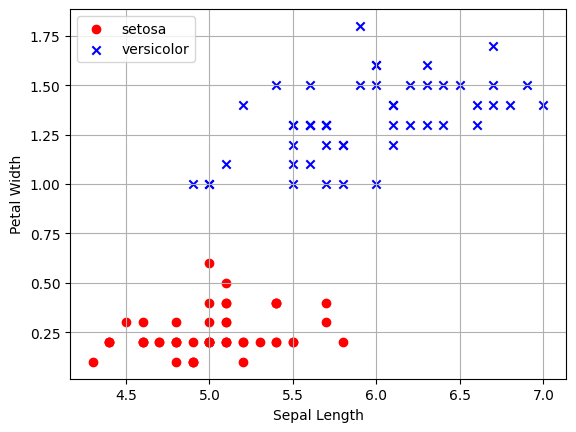

In [3]:
# column 0 = sepal length, column 3 = petal width
a, b = 0, 3
plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='versicolor')

plt.xlabel('Sepal Length')
plt.ylabel('Petal Width')
plt.legend(loc='upper left')
plt.grid()
plt.show()

### Step 3 - Create Perceptron Class

Implementasi mengikuti bentuk paling sederhana dari Perceptron Rosenblatt:

* `net_input(x) = w·x + b`
* `predict(x) = 1 jika net_input >= 0, selain itu -1`
* pembaruan bobot: `w += eta * (target - prediction) * x`

Bobot hanya diperbarui ketika prediksi salah, sehingga `errors_` mencatat jumlah *update* per epoch.

In [4]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):

        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

### Step 4 - Select Data and Encode Labels

Hanya 100 data pertama (setosa dan versicolor) yang dipakai. Label diubah menjadi
`-1` (setosa) dan `+1` (versicolor). Dua fitur yang dipakai adalah **sepal length** dan
**petal width**, karena keduanya memisahkan kedua kelas dengan cukup baik.

In [5]:
y = df.iloc[0:100, 4].values            # select the first 100 data points
y = np.where(y == 'Iris-setosa', -1, 1)  # change label encoding
X = df.iloc[0:100, [0, 3]].values        # slice training data

print("X shape:", X.shape)
print("Label unik:", np.unique(y))

X shape: (100, 2)
Label unik: [-1  1]


### Step 5 - Fit the Model

In [6]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

print("Bobot (bias, w1, w2):", ppn.w_)
print("Jumlah update per epoch:", ppn.errors_)

Bobot (bias, w1, w2): [-0.4  -0.1   1.12]
Jumlah update per epoch: [2, 2, 2, 3, 2, 1, 0, 0, 0, 0]


### Step 6 - Visualize Error Value per Epoch

Jumlah *update* bobot per epoch menunjukkan seberapa cepat model konvergen. Jika mencapai 0,
data terpisah secara linear dan model sudah stabil.

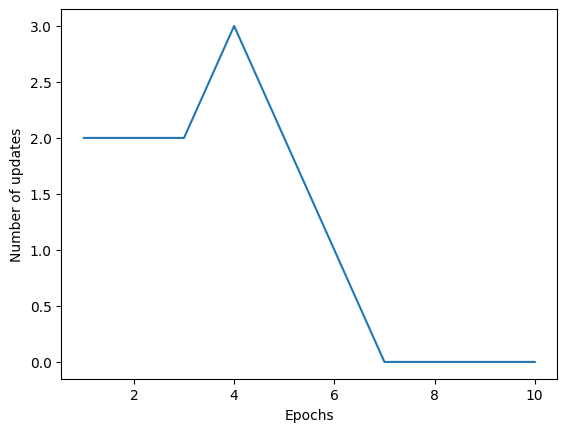

In [7]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.show()

### Step 7 - Visualize the Decision Boundary

In [8]:
# create a function to plot the decision regions

from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions by creating a pair of grid arrays xx1 and xx2 via meshgrid function in Numpy
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))

    # use predict method to predict the class labels z of the grid points
    Z = classifier.predict(np.array([xx1.ravel(),xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # draw the contour using matplotlib
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, color=cmap(i), marker=markers[i], label=cl)

    plt.xlabel('Sepal Length')
    plt.ylabel('Petal Width')
    plt.legend(loc='upper left')

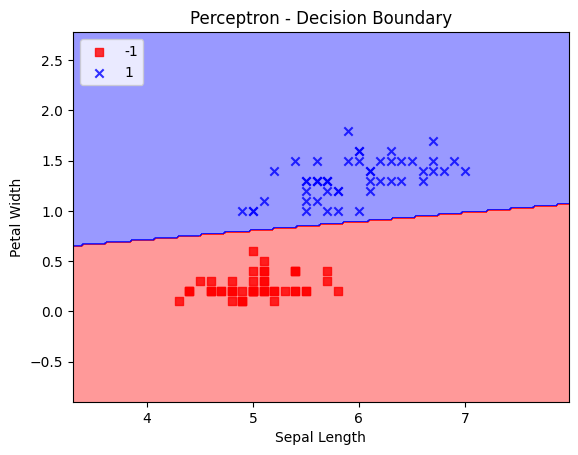

In [9]:
plot_decision_regions(X, y, classifier=ppn)
plt.title('Perceptron - Decision Boundary')
plt.show()

### Step 8 - Evaluate the Model

Karena data latihnya *linearly separable* dan model konvergen, akurasi pada data latih
mencapai 100%. Perlu diingat bahwa ini bukan ukuran generalisasi - evaluasi yang benar
memerlukan data uji terpisah.

In [10]:
pred = ppn.predict(X)
accuracy = np.mean(pred == y)
print("Akurasi pada data latih:", accuracy)
print("Jumlah salah klasifikasi:", int(np.sum(pred != y)))

Akurasi pada data latih: 1.0
Jumlah salah klasifikasi: 0


### Step 9 - Experiment: Effect of Learning Rate and Epochs

Nilai `eta` menentukan besar langkah pembaruan bobot, sedangkan `n_iter` adalah jumlah epoch.
Berikut perbandingan beberapa kombinasi pada data yang sama.

In [11]:
rows = []
for eta in [0.001, 0.01, 0.1, 1.0]:
    for n_iter in [5, 10, 20]:
        model = Perceptron(eta=eta, n_iter=n_iter).fit(X, y)
        acc = np.mean(model.predict(X) == y)
        rows.append((eta, n_iter, model.errors_[-1], acc))

print(f"{'eta':>6} | {'n_iter':>6} | {'updates akhir':>13} | {'akurasi':>8}")
print("-" * 44)
for eta, n_iter, last_err, acc in rows:
    print(f"{eta:>6} | {n_iter:>6} | {last_err:>13} | {acc:>8.2f}")

   eta | n_iter | updates akhir |  akurasi
--------------------------------------------
 0.001 |      5 |             2 |     0.50
 0.001 |     10 |             0 |     1.00
 0.001 |     20 |             0 |     1.00
  0.01 |      5 |             2 |     0.50
  0.01 |     10 |             0 |     1.00
  0.01 |     20 |             0 |     1.00
   0.1 |      5 |             2 |     0.50
   0.1 |     10 |             0 |     1.00
   0.1 |     20 |             0 |     1.00
   1.0 |      5 |             2 |     0.50
   1.0 |     10 |             0 |     1.00
   1.0 |     20 |             0 |     1.00


### Step 10 - Conclusion

* Perceptron hanya dapat memisahkan data yang *linearly separable*; dengan dua fitur yang dipakai,
  setosa dan versicolor terpisah dengan baik sehingga model konvergen.
* Pada data yang *linearly separable*, **jumlah update per epoch tidak bergantung pada `eta`**:
  yang menentukan hanya apakah prediksi salah atau benar. Perbedaan `eta` hanya mengubah **skala**
  vektor bobot, bukan arah batas keputusan. Hasil percobaan menunjukkan hal ini - semua nilai `eta`
  berhenti pada jumlah update yang sama.
* Yang benar-benar menentukan adalah **jumlah epoch**: pada `n_iter = 5` model belum konvergen
  (akurasi 0.50), sedangkan pada `n_iter >= 10` sudah mencapai akurasi 1.0.
* Batas keputusan yang dihasilkan selalu berupa **garis lurus** - keterbatasan utama Perceptron
  yang menjadi motivasi munculnya MLP pada lab berikutnya.